## Assignment 2 - Dynamics on Networks: Thresholds and Spreading


# Introduction

This assignment examines how information spreads through a network of pro-Kremlin and anti-Kremlin Telegram channels. Using an empirical repost network, we apply a threshold-based contagion model to investigate how network structure and initial adoption conditions shape diffusion.

The model assumes that a channel adopts information when a sufficient fraction of its connected neighbours has already adopted it. This allows us to examine how reinforcement between connected channels can generate large-scale cascades.

The analysis focuses on four main questions:

- **Seeding strategies:** How does the choice of initial adopters affect cascade size and speed?
- **Adoption thresholds:** How sensitive is information diffusion to changes in the required level of reinforcement?
- **Threshold heterogeneity:** How does variation in individual adoption thresholds affect cascade dynamics?
- **Network structure:** How do network connections and centrality influence the potential spread of information?

The overall objective is to identify the conditions under which small initial seed groups can trigger large cascades and to explore the implications for monitoring information diffusion in politically polarised online environments.


### Step 0. Network Setup
- Here we examine the network structure and extract its Largest Connected Component (LCC) to prepare the network for the simulations.

In [2]:

# Import libraries
import numpy as np
import pandas as pd
import networkx as nx
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from pathlib import Path

SEED = 42

# Load network data
nodes_data = pd.read_csv("cosmograph_nodes.csv")
edges_data = pd.read_csv("cosmograph_edges.csv")

# Construct an undirected, unweighted graph
G_full = nx.Graph()
G_full.add_nodes_from(nodes_data["id"])
G_full.add_edges_from(
    zip(edges_data["source"], edges_data["target"])
)

# Extract the Largest Connected Component (LCC)
largest_component = max(
    nx.connected_components(G_full),
    key=len
)
G = G_full.subgraph(largest_component).copy()

# Fix node ordering and create adjacency matrix
nodes = sorted(G.nodes())
N = len(nodes)
M = G.number_of_edges()

A = nx.to_numpy_array(
    G,
    nodelist=nodes,
    weight=None
)

# Basic network statistics
mean_degree = 2 * M / N

print(f"Largest Connected Component: {N} nodes, {M} edges")
print(f"Mean degree: {mean_degree:.2f}")

Largest Connected Component: 439 nodes, 7449 edges
Mean degree: 33.94


### Step 1. Implement the Fractional Threshold Model
- Here we implement the rules that determine how inactive nodes become active based on the activity of their neighbours, allowing us to simulate and compare different adoption thresholds.

In [3]:

# Functions for the fractional threshold model

def run_model(adj, seed_idx, thr, t_max=200):
    n = adj.shape[0]

    # Calculate node degrees
    deg = adj.sum(axis=1)
    has_nb = deg > 0
    safe_deg = np.where(has_nb, deg, 1.0)

    # Prepare thresholds
    thresholds = np.asarray(thr, dtype=float)

    if thresholds.ndim == 0:
        thresholds = np.full(n, thresholds)

    if thresholds.shape != (n,):
        raise ValueError("Thresholds must be a scalar or an array of length N.")

    if np.any((thresholds < 0) | (thresholds > 1)):
        raise ValueError("Thresholds must be between 0 and 1.")

    # Initialise node states
    state = np.zeros(n, dtype=int)
    state[seed_idx] = 1

    when = np.full(n, np.nan)
    when[seed_idx] = 0

    trajectory = [state.mean()]
    t_star = 0
    hit_tmax = True

    # Synchronous updating
    for t in range(1, t_max + 1):

        # Fraction of active neighbours at time t
        share_active = (adj @ state) / safe_deg

        # Identify newly adopting nodes
        adopt = has_nb & (share_active >= thresholds)

        # Apply all updates simultaneously
        new_state = np.maximum(state, adopt.astype(int))

        # Check for steady state
        if np.array_equal(new_state, state):
            hit_tmax = False
            break

        # Record adoption times
        new_adopters = (new_state == 1) & (state == 0)
        when[new_adopters] = t

        state = new_state
        trajectory.append(state.mean())
        t_star = t

    return (
        np.array(trajectory),
        state.mean(),
        t_star,
        hit_tmax,
        when
    )


# Seeding functions

def random_seeds(k, rng):
    return rng.choice(N, size=k, replace=False)


def top_k(scores, k):
    order = sorted(
        range(N),
        key=lambda i: (-scores[i], nodes[i])
    )
    return np.array(order[:k])


# Threshold configurations

def homogeneous(tau):
    return np.full(N, tau)


def heterogeneous(rng):
    return rng.uniform(0, 1, size=N)


# Time to reach 50% adoption

def t_to_half(traj):
    idx = np.where(traj >= 0.5)[0]
    return idx[0] if len(idx) else np.nan


# Mean trajectory and 95% confidence interval

def mean_ci(results):
    L = max(len(r[0]) for r in results)

    mat = np.array([
        np.pad(
            r[0],
            (0, L - len(r[0])),
            mode="edge"
        )
        for r in results
    ])

    mean = mat.mean(axis=0)
    ci = 1.96 * mat.std(axis=0, ddof=1) / np.sqrt(len(mat))

    return mean, ci


# Plot adoption trajectories

def plot_curve(ax, data, label, fmt="-"):
    if isinstance(data, list):
        mean, ci = mean_ci(data)
    else:
        mean, ci = data, None

    t = np.arange(len(mean))

    ax.plot(
        t, mean, fmt,
        marker="o",
        markersize=3,
        label=label
    )

    if ci is not None:
        ax.fill_between(
            t,
            np.clip(mean - ci, 0, 1),
            np.clip(mean + ci, 0, 1),
            alpha=0.2
        )
print("All functions defined successfully.")

All functions defined successfully.



#### Baseline Simulation

Here we compare homogeneous and heterogeneous thresholds under the same baseline conditions (\(f_0 = 0.05\), \(\tau = 0.2\)). We run 100 simulations to examine differences in cascade size, global cascade probability, and convergence time.


,Mean final adoption,SD final adoption,Global cascade probability,Mean convergence time,Runs reaching t_max
Homogeneous,0.429,0.440,0.37,7.47,0.0
Heterogeneous,0.520,0.264,0.49,16.41,0.0


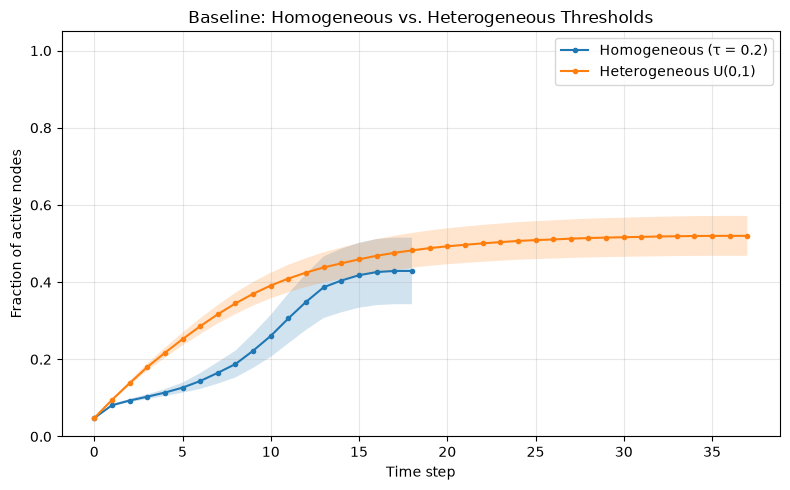

In [4]:

# Baseline: homogeneous vs heterogeneous thresholds

N_RUNS = 100
F0 = 0.05
K = int(F0 * N)
TAU = 0.2

# Generate shared initial seed sets
rng_seeds = np.random.default_rng(SEED + 1)
seed_sets = [
    random_seeds(K, rng_seeds)
    for _ in range(N_RUNS)
]

# Run homogeneous and heterogeneous simulations
hom_results = []
het_results = []

rng_het = np.random.default_rng(SEED + 2)

for seeds in seed_sets:

    # Homogeneous thresholds
    hom_results.append(
        run_model(A, seeds, homogeneous(TAU))
    )

    # Heterogeneous thresholds
    het_thresholds = heterogeneous(rng_het)

    het_results.append(
        run_model(A, seeds, het_thresholds)
    )


# Calculate summary statistics
def summarize_results(results):
    final_sizes = np.array([r[1] for r in results])
    convergence = np.array([r[2] for r in results])
    global_cascades = final_sizes > 0.5

    return {
        "Mean final adoption": final_sizes.mean(),
        "SD final adoption": final_sizes.std(ddof=1),
        "Global cascade probability": global_cascades.mean(),
        "Mean convergence time": convergence.mean(),
        "Runs reaching t_max": sum(r[3] for r in results)
    }


baseline_summary = pd.DataFrame({
    "Homogeneous": summarize_results(hom_results),
    "Heterogeneous": summarize_results(het_results)
}).T

display(baseline_summary.round(3))


# Plot mean adoption trajectories
fig, ax = plt.subplots(figsize=(8, 5))

plot_curve(ax, hom_results, "Homogeneous (τ = 0.2)")
plot_curve(ax, het_results, "Heterogeneous U(0,1)")

ax.set(
    xlabel="Time step",
    ylabel="Fraction of active nodes",
    title="Baseline: Homogeneous vs. Heterogeneous Thresholds",
    ylim=(0, 1.05)
)

ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Step 2. Compare Initial Seeding Strategies
- Here we test three seeding strategies (random, degree-based, and betweenness-based) using the same initial seed fraction to compare their impact on cascade size, convergence time, and adoption dynamics, averaging multiple runs for random seeding.

Network: 439 nodes
Adjacency matrix correctly aligned with graph.
Initial seeds: 8 (1.82% of the network)
Threshold: 0.2
Random simulations: 100


,Final adoption,SD,Mean T*,Step to 50%
Random,0.055,0.136,2.64,16.0
Degree,1.000,NaN,8.00,5.0
Betweenness,1.000,NaN,7.00,4.0


Random simulations reaching 50%: 2 out of 100
Mean step among successful simulations: 16.0


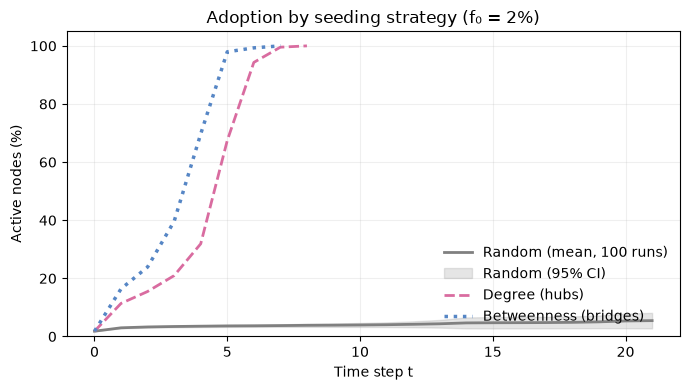

In [5]:

# Seeding strategy comparison (f0 = 2%, tau = 0.2)

# Rebuild adjacency matrix using exactly the same node order
nodes = list(G.nodes())
N = len(nodes)
A = nx.to_numpy_array(G, nodelist=nodes, weight=None)

# Verify node order and degree consistency
deg_scores = A.sum(axis=1)
graph_degrees = np.array([G.degree(v) for v in nodes])

assert np.array_equal(deg_scores, graph_degrees), \
    "Error: adjacency matrix and graph node order do not match!"

print(f"Network: {N} nodes")
print("Adjacency matrix correctly aligned with graph.")

# Initial seeds and model parameters
F0_COMPARE = 0.02
K2 = int(F0_COMPARE * N)
rng = np.random.default_rng(SEED + 2)

print(f"Initial seeds: {K2} ({K2 / N:.2%} of the network)")
print(f"Threshold: {TAU}")
print(f"Random simulations: {N_RUNS}")

# Random seeding: 100 independent simulations
rand_res = [
    run_model(A, random_seeds(K2, rng), homogeneous(TAU))
    for _ in range(N_RUNS)
]

# Degree-based seeding
deg_seeds = top_k(deg_scores, K2)
deg_res = run_model(A, deg_seeds, homogeneous(TAU))

# Betweenness-based seeding
bc = nx.betweenness_centrality(G, weight=None)
btw_scores = np.array([bc[v] for v in nodes])
btw_seeds = top_k(btw_scores, K2)
btw_res = run_model(A, btw_seeds, homogeneous(TAU))

# Results table
rand_s = np.array([r[1] for r in rand_res])

table2 = pd.DataFrame({
    "Final adoption": [
        rand_s.mean(),
        deg_res[1],
        btw_res[1]
    ],
    "SD": [
        rand_s.std(ddof=1),
        np.nan,
        np.nan
    ],
    "Mean T*": [
        np.mean([r[2] for r in rand_res]),
        deg_res[2],
        btw_res[2]
    ],
    "Step to 50%": [
        np.nanmean([t_to_half(r[0]) for r in rand_res]),
        t_to_half(deg_res[0]),
        t_to_half(btw_res[0])
    ]
}, index=["Random", "Degree", "Betweenness"])

display(table2.round(3))

# Check random simulations reaching 50% adoption
random_steps = [t_to_half(r[0]) for r in rand_res]
successful_steps = [s for s in random_steps if not np.isnan(s)]

print(f"Random simulations reaching 50%: "
      f"{len(successful_steps)} out of {N_RUNS}")

if successful_steps:
    print(f"Mean step among successful simulations: "
          f"{np.mean(successful_steps):.1f}")

# Plot adoption trajectories with 95% confidence interval
random_mean, random_ci = mean_ci(rand_res)

fig, ax = plt.subplots(figsize=(7, 4))

t = np.arange(len(random_mean))

# Random: mean trajectory
ax.plot(
    t,
    random_mean * 100,
    color="grey",
    linewidth=2,
    label=f"Random (mean, {N_RUNS} runs)"
)

# Random: 95% confidence interval
ax.fill_between(
    t,
    np.clip(random_mean - random_ci, 0, 1) * 100,
    np.clip(random_mean + random_ci, 0, 1) * 100,
    color="grey",
    alpha=0.2,
    label="Random (95% CI)"
)

# Degree-based strategy
ax.plot(
    deg_res[0] * 100,
    "--",
    color="#D96CA0",
    linewidth=2,
    label="Degree (hubs)"
)

# Betweenness-based strategy
ax.plot(
    btw_res[0] * 100,
    ":",
    color="#5686C5",
    linewidth=2.5,
    label="Betweenness (bridges)"
)

ax.set(
    xlabel="Time step t",
    ylabel="Active nodes (%)",
    title=f"Adoption by seeding strategy (f₀ = {F0_COMPARE:.0%})",
    ylim=(0, 105)
)

ax.grid(alpha=0.2)
ax.legend(loc="lower right", frameon=False)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "seeding_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


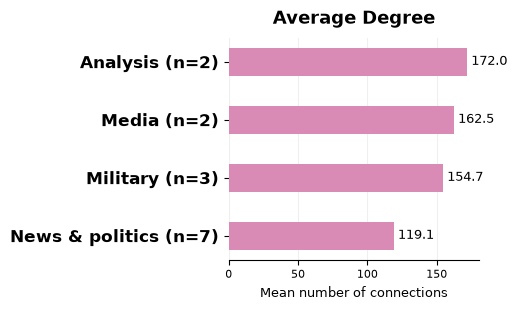

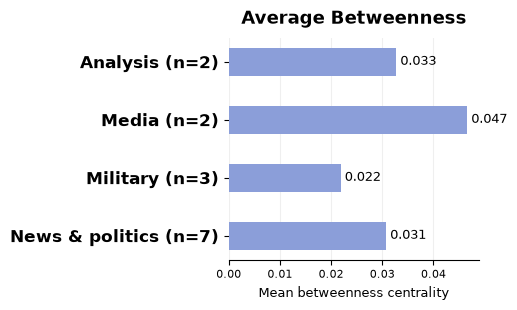

Channels included in each category:

News & politics (n=7):
@sergeykolyasnikov, @karaulny, @russica2, @sidpolit, @kaktovottak, @bbbreaking, @eshkinkrot

Military (n=3):
@sashakots, @boris_rozhin, @rybar

Media (n=2):
@t34newsfeed, @solovievlive

Analysis (n=2):
@rus_demiurge, @dr_alex_sosnowski


In [6]:
DATA = Path.cwd()

# 1. Load network and calculate centrality
edges = pd.read_csv(DATA / "cosmograph_edges.csv")
G = nx.from_pandas_edgelist(edges, "source", "target")

nodes = list(G.nodes())

df = pd.DataFrame({
    "username": nodes,
    "degree": [G.degree(n) for n in nodes],
    "betweenness": list(nx.betweenness_centrality(G).values())
})

# 2. Assign channel categories
types = {
    "rus_demiurge": "Analysis",
    "dr_alex_sosnowski": "Analysis",
    "sashakots": "Military",
    "rybar": "Military",
    "boris_rozhin": "Military",
    "solovievlive": "Media",
    "t34newsfeed": "Media"
}

def clean(x):
    return str(x).lower().strip().replace("@", "").replace(
        "https://t.me/", ""
    ).strip("/")

df["username"] = df["username"].apply(clean)
df["category"] = df["username"].map(types).fillna("News & politics")

# 3. Select channels appearing in either Top 10
top = pd.concat([
    df.nlargest(10, "degree"),
    df.nlargest(10, "betweenness")
]).drop_duplicates("username")

# 4. Calculate average centrality by category
summary = top.groupby("category").agg(
    mean_degree=("degree", "mean"),
    mean_betweenness=("betweenness", "mean"),
    channels=("username", lambda x: ", ".join("@" + n for n in x)),
    count=("username", "count")
).sort_values("mean_degree")



# 5. Create two compact figures

categories = [
    f"{category} (n={count})"
    for category, count in zip(summary.index, summary["count"])
]

# Figure 1: Average Degree
fig, ax = plt.subplots(figsize=(5.2, 3.2))

bars = ax.barh(
    categories,
    summary["mean_degree"],
    color="#D98BB5",
    height=0.48
)

ax.set_title("Average Degree",
             fontsize=13, fontweight="bold", pad=10)
ax.set_xlabel("Mean number of connections", fontsize=9)

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=8)

for label in ax.get_yticklabels():
    label.set_fontweight("bold")

for bar, value in zip(bars, summary["mean_degree"]):
    ax.text(
        bar.get_width(), bar.get_y() + bar.get_height() / 2,
        f" {value:.1f}", va="center", fontsize=9
    )

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.savefig(DATA / "average_degree_by_category.png",
            dpi=300, bbox_inches="tight")
plt.show()


# Figure 2: Average Betweenness
fig, ax = plt.subplots(figsize=(5.2, 3.2))

bars = ax.barh(
    categories,
    summary["mean_betweenness"],
    color="#8B9ED9",
    height=0.48
)

ax.set_title("Average Betweenness",
             fontsize=13, fontweight="bold", pad=10)
ax.set_xlabel("Mean betweenness centrality", fontsize=9)

ax.tick_params(axis="y", labelsize=12)
ax.tick_params(axis="x", labelsize=8)

for label in ax.get_yticklabels():
    label.set_fontweight("bold")

for bar, value in zip(bars, summary["mean_betweenness"]):
    ax.text(
        bar.get_width(), bar.get_y() + bar.get_height() / 2,
        f" {value:.3f}", va="center", fontsize=9
    )

ax.grid(axis="x", alpha=0.2)
ax.set_axisbelow(True)
ax.spines[["top", "right", "left"]].set_visible(False)

plt.tight_layout()
plt.savefig(DATA / "average_betweenness_by_category.png",
            dpi=300, bbox_inches="tight")
plt.show()


# 6. Print channels included in each category
print("Channels included in each category:")
for category, row in summary.iterrows():
    print(f"\n{category} (n={row['count']}):")
    print(row["channels"])


### Step 3. Experimental Design and Parameter Exploration

- Here we vary the adoption threshold and initial seed fraction to examine their effects on cascade size and identify conditions that lead to large-scale diffusion.

In [7]:
# Experiment A: threshold sensitivity sweep

TAU_GRID = np.round(np.arange(0.05, 0.501, 0.01), 2)

# Use the same initial seed sets across all threshold values
# seed_sets were generated in Step 1 (5% initial seeds)

outcome = np.zeros((len(TAU_GRID), N_RUNS))
sweep_rows = []

for i, tau in enumerate(TAU_GRID):

    results = [
        run_model(A, seeds, homogeneous(tau))
        for seeds in seed_sets
    ]

    final_sizes = np.array([r[1] for r in results])

    outcome[i, :] = final_sizes > 0.5

    sweep_rows.append({
        "tau": tau,
        "Mean S_inf": final_sizes.mean(),
        "SD": final_sizes.std(ddof=1),
        "P(global)": outcome[i, :].mean(),
        "Mean T*": np.mean([r[2] for r in results])
    })


sweep = pd.DataFrame(sweep_rows)

display(sweep.round(3))

,tau,Mean S_inf,SD,P(global),Mean T*
0,0.05,1.000,0.000,1.00,3.55
1,0.06,1.000,0.000,1.00,3.84
2,0.07,1.000,0.000,1.00,3.99
3,0.08,1.000,0.000,1.00,4.17
4,0.09,1.000,0.000,1.00,4.36
5,0.10,1.000,0.000,1.00,4.59
6,0.11,1.000,0.000,1.00,5.05
7,0.12,0.991,0.092,0.99,5.84
8,0.13,0.982,0.128,0.98,6.53
9,0.14,0.973,0.157,0.97,7.34


Estimated tau_c: 0.181
95% Bootstrap CI: [0.176, 0.188]


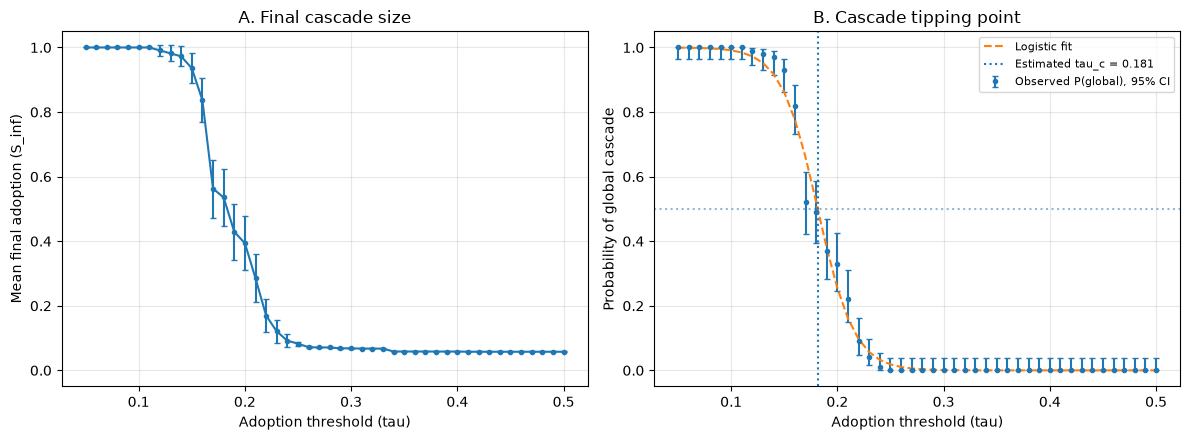

In [8]:

from scipy.optimize import curve_fit
from statsmodels.stats.proportion import proportion_confint

# Logistic function
def logistic(x, x0, k):
    return 1 / (1 + np.exp(k * (x - x0)))

# Fit logistic curve to the probability of a global cascade
popt, _ = curve_fit(
    logistic,
    TAU_GRID,
    sweep["P(global)"],
    p0=[0.18, 50],
    bounds=([0.05, 0.01], [0.50, 500]),
    maxfev=20000
)

tau_c = popt[0]

# Bootstrap confidence interval for tau_c
rng_boot = np.random.default_rng(SEED + 3)
boot = []

for _ in range(2000):
    idx = rng_boot.integers(0, N_RUNS, N_RUNS)

    p_boot = outcome[:, idx].mean(axis=1)

    try:
        p, _ = curve_fit(
            logistic,
            TAU_GRID,
            p_boot,
            p0=[tau_c, popt[1]],
            bounds=([0.05, 0.01], [0.50, 500]),
            maxfev=10000
        )
        boot.append(p[0])
    except (RuntimeError, ValueError):
        continue

ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

print(f"Estimated tau_c: {tau_c:.3f}")
print(f"95% Bootstrap CI: [{ci_low:.3f}, {ci_high:.3f}]")

# Confidence intervals for P(global): Wilson intervals
successes = outcome.sum(axis=1)

p_low, p_high = proportion_confint(
    successes,
    N_RUNS,
    alpha=0.05,
    method="wilson"
)

# Two-panel visualization
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Panel A: Mean final adoption
axes[0].errorbar(
    sweep["tau"],
    sweep["Mean S_inf"],
    yerr=1.96 * sweep["SD"] / np.sqrt(N_RUNS),
    marker="o",
    markersize=3,
    capsize=2
)

axes[0].set(
    xlabel="Adoption threshold (tau)",
    ylabel="Mean final adoption (S_inf)",
    title="A. Final cascade size",
    ylim=(-0.05, 1.05)
)
axes[0].grid(alpha=0.3)

# Panel B: Probability of global cascade
axes[1].errorbar(
    TAU_GRID,
    sweep["P(global)"],
    yerr=[
        sweep["P(global)"] - p_low,
        p_high - sweep["P(global)"]
    ],
    fmt="o",
    markersize=3,
    capsize=2,
    label="Observed P(global), 95% CI"
)

axes[1].plot(
    TAU_GRID,
    logistic(TAU_GRID, *popt),
    "--",
    label="Logistic fit"
)

axes[1].axvline(
    tau_c,
    linestyle=":",
    label=f"Estimated tau_c = {tau_c:.3f}"
)

axes[1].axhline(0.5, linestyle=":", alpha=0.5)

axes[1].set(
    xlabel="Adoption threshold (tau)",
    ylabel="Probability of global cascade",
    title="B. Cascade tipping point",
    ylim=(-0.05, 1.05)
)
axes[1].grid(alpha=0.3)
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()


,f0,Model,Mean S_inf,SD,P(global),Mean T*
0,0.01,Homogeneous,0.017,0.009,0.00,1.35
1,0.01,Heterogeneous,0.130,0.199,0.08,7.40
2,0.02,Homogeneous,0.048,0.099,0.01,2.60
3,0.02,Heterogeneous,0.229,0.241,0.15,10.77
4,0.05,Homogeneous,0.444,0.438,0.38,7.80
5,0.05,Heterogeneous,0.421,0.244,0.38,12.82
6,0.10,Homogeneous,0.992,0.082,0.99,6.99
7,0.10,Heterogeneous,0.680,0.191,0.79,16.28


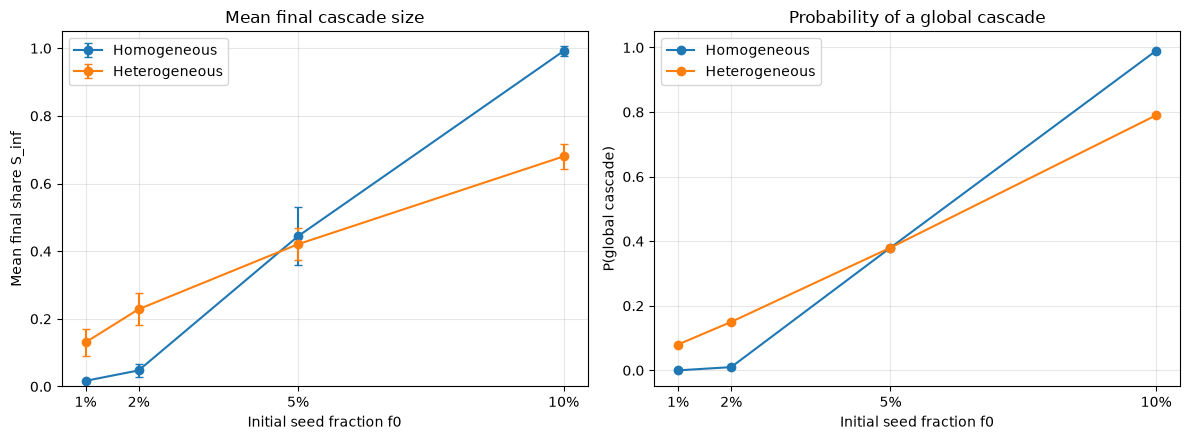

In [9]:

# Experiment B: seed fraction sweep

SEED_FRACTIONS = [0.01, 0.02, 0.05, 0.10]
TAU_FIXED = 0.2

rng_f0 = np.random.default_rng(SEED + 4)
rng_f0_het = np.random.default_rng(SEED + 5)

# Generate one random ordering and one threshold vector per run.
# This allows us to compare different seed fractions under
# the same underlying random conditions.

seed_orders = [
    rng_f0.permutation(N)
    for _ in range(N_RUNS)
]

threshold_vectors = [
    heterogeneous(rng_f0_het)
    for _ in range(N_RUNS)
]

f0_rows = []

for f0 in SEED_FRACTIONS:
    k = int(f0 * N)

    hom = []
    het = []

    for run in range(N_RUNS):
        seeds = seed_orders[run][:k]

        hom.append(
            run_model(A, seeds, homogeneous(TAU_FIXED))
        )

        het.append(
            run_model(A, seeds, threshold_vectors[run])
        )

    for name, res in [
        ("Homogeneous", hom),
        ("Heterogeneous", het)
    ]:
        s_inf = np.array([r[1] for r in res])

        f0_rows.append({
            "f0": f0,
            "Model": name,
            "Mean S_inf": s_inf.mean(),
            "SD": s_inf.std(ddof=1),
            "P(global)": (s_inf > 0.5).mean(),
            "Mean T*": np.mean([r[2] for r in res]),
        })

f0_df = pd.DataFrame(f0_rows)
display(f0_df.round(3))


# Plot 1: Mean final cascade size

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

for name in ["Homogeneous", "Heterogeneous"]:
    sub = f0_df[f0_df["Model"] == name]

    axes[0].errorbar(
        sub["f0"],
        sub["Mean S_inf"],
        yerr=1.96 * sub["SD"] / np.sqrt(N_RUNS),
        marker="o",
        capsize=3,
        label=name
    )

axes[0].set_xticks(SEED_FRACTIONS)
axes[0].set_xticklabels([f"{f:.0%}" for f in SEED_FRACTIONS])
axes[0].set(
    xlabel="Initial seed fraction f0",
    ylabel="Mean final share S_inf",
    title="Mean final cascade size",
    ylim=(0, 1.05)
)
axes[0].grid(alpha=0.3)
axes[0].legend()


# Plot 2: Probability of a global cascade

for name in ["Homogeneous", "Heterogeneous"]:
    sub = f0_df[f0_df["Model"] == name]

    axes[1].plot(
        sub["f0"],
        sub["P(global)"],
        marker="o",
        label=name
    )

axes[1].set_xticks(SEED_FRACTIONS)
axes[1].set_xticklabels([f"{f:.0%}" for f in SEED_FRACTIONS])
axes[1].set(
    xlabel="Initial seed fraction f0",
    ylabel="P(global cascade)",
    title="Probability of a global cascade",
    ylim=(-0.05, 1.05)
)
axes[1].grid(alpha=0.3)
axes[1].legend()

plt.tight_layout()
plt.show()


### Step 4: Network Topology and Null Model

- Here we compare the empirical network (largest connected component) against a degree-preserving null model to analyse which topological properties emerge beyond the node degree distribution alone.

In [10]:

# 1. Reconstruct the Largest Connected Component
G_step4 = G_full.subgraph(
    max(nx.connected_components(G_full), key=len)
).copy()

# 2. Create a degree-preserving null model
G_null = G_step4.copy()

nx.double_edge_swap(
    G_null,
    nswap=10 * G_null.number_of_edges(),
    max_tries=100 * G_null.number_of_edges(),
    seed=SEED
)

# 3. Calculate network topology indicators
def network_metrics(graph):

    degrees = np.array([d for _, d in graph.degree()])

    largest_cc = graph.subgraph(
        max(nx.connected_components(graph), key=len)
    )

    return {
        "Degree heterogeneity (CV)": degrees.std() / degrees.mean(),
        "Clustering": nx.average_clustering(graph),
        "Assortativity": nx.degree_assortativity_coefficient(graph),
        "Average path length": nx.average_shortest_path_length(largest_cc)
    }


# 4. Compare empirical network and null model
comparison = pd.DataFrame({
    "Empirical network": network_metrics(G_step4),
    "Null model": network_metrics(G_null)
})

print("Network topology comparison:")
display(comparison.round(3))


Network topology comparison:


,Empirical network,Null model
Degree heterogeneity (CV),1.095,1.095
Clustering,0.412,0.372
Assortativity,-0.098,-0.204
Average path length,2.372,2.213
